Code: https://github.com/zhurleonid/corporate-risk-management
(`homework_3/part1_var_estimation/hw3_part1_code.ipynb`)

Homework 3 comes as three problem sheets; this is sheet 1, numbered Q1 to
Q6 as on the sheet. The write-up is below. The code is appended at
the end. The derivations, Q2 (weights), Q3 (the three loss operators) and
Q5 (the analytic VaR of the linearized loss), are handwritten and attached
separately; the write-up points to them where they belong.

# VaR estimation of a market-cap-weighted portfolio

## Q1. Data

Daily closes for MSFT, AAPL and GOOGL from Yahoo Finance, 05/23/2024 through
05/22/2026, saved to `stocks_daily.csv`. There are $N = 501$ trading days and
therefore $500$ daily log returns $X_i = \ln(S_i/S_{i-1})$ per stock.

$$\begin{array}{l r r r}
\hline
\text{Date} & \text{MSFT} & \text{AAPL} & \text{GOOGL} \\
\hline
\text{2024-05-23} & 427.00 & 186.88 & 173.55 \\
\text{2024-05-24} & 430.16 & 189.98 & 174.99 \\
\text{2024-05-28} & 430.32 & 189.99 & 176.40 \\
\text{2024-05-29} & 429.17 & 190.29 & 175.90 \\
\text{2024-05-30} & 414.67 & 191.29 & 172.11 \\
\hline
\text{2026-05-18} & 423.54 & 297.84 & 396.94 \\
\text{2026-05-19} & 417.42 & 298.97 & 387.66 \\
\text{2026-05-20} & 421.06 & 302.25 & 388.91 \\
\text{2026-05-21} & 419.09 & 304.99 & 387.66 \\
\text{2026-05-22} & 418.57 & 308.82 & 382.97 \\
\hline
\end{array}$$

*First and last five closes. $N = 501$ observations.*

## Q2. Market-cap weights

> **Q2: by hand, attached.**

## Q3. Empirical VaR under the three loss operators

> **Q3: the three loss operators by hand, attached.** The VaR from a sample
> of $n$ losses is the $\lceil n\alpha \rceil$-th order statistic.

### Pseudocode

```
read closes, form log returns x_1 ... x_n    (n = 500 rows, 3 cols)
w = cap / sum(cap),  V = 1,000,000

operators, x a row of three log returns:
    full(x) = -V * sum_i w_i * (exp(x_i) - 1)
    lin(x)  = -V * sum_i w_i * x_i
    quad(x) = -V * sum_i w_i * (x_i + x_i^2 / 2)

for each operator l in {full, lin, quad}:
    for i = 1 ... n:
        loss_i = l(x_i)              one scalar loss per historical day
    sort:  loss_(1) <= ... <= loss_(n)
    VaR = loss_(ceil(n*alpha))       the 475th order statistic
```

### Results

$$\begin{array}{l r r r}
\hline
\text{Operator} & \text{VaR}_{0.95} & \text{mean} & \text{s.d.} \\
\hline
\text{Full} & 21{,}043.04 & -1{,}116.04 & 13{,}918.52 \\
\text{Linearized} & 21{,}415.73 & -958.72 & 13{,}831.42 \\
\text{Quadratic} & 21{,}038.61 & -1{,}115.59 & 13{,}910.40 \\
\hline
\end{array}$$

*Historical simulation, $n = 500$, in dollars.*

The linearized VaR is 1.8% above the full one, as the attached derivation
predicts. The quadratic VaR is within 0.02% of the full one. Daily log returns
are of order 1%, so the $x^2$ terms are of order $10^{-4}$ and the cubic
remainder of order $10^{-6}$; at a 95% confidence level there is nothing left
for the quadratic operator to miss.

## Q4. EWMA mean vector and covariance matrix

The recursions, run through all 500 returns from $\mu_0 = 0$, $\Sigma_0 = 0$
with $\lambda = \theta = 0.97$:

$$\mu_{t+\Delta} = \lambda \mu_t + (1-\lambda) X_t, \qquad
\Sigma_{t+\Delta} = \theta \Sigma_t + (1-\theta)(X_t - \mu_t)(X_t - \mu_t)^{\top}.$$

The covariance update uses $\mu_t$, the mean before it is updated with $X_t$,
so the code computes the deviation first. After 500 steps the weight left on
the starting values is $0.97^{500} = 2.4 \times 10^{-7}$, so the choice of
$\mu_0 = \Sigma_0 = 0$ has no effect on the result.

### Pseudocode

```
mu = (0, 0, 0),  Sigma = 3x3 zero matrix
for i = 1 ... n:
    d     = x_i - mu                     deviation from the OLD mean
    Sigma = theta*Sigma + (1 - theta) * d d^T
    mu    = lambda*mu + (1 - lambda) * x_i
output mu, Sigma                         estimates as of 05/22/2026
```

### Results

As of 05/22/2026, for use over 05/22/2026 to 05/25/2026 (the next trading
day):

$$\begin{array}{l r r r r}
\hline
 & \mu \text{ (daily)} & \text{ann. vol} & \text{corr. MSFT} & \text{corr. AAPL} \\
\hline
\text{MSFT} & 4.73 \times 10^{-4} & 28.14\% & 1 & \\
\text{AAPL} & 3.64 \times 10^{-3} & 22.04\% & 0.139 & 1 \\
\text{GOOGL} & 3.31 \times 10^{-3} & 34.02\% & 0.009 & 0.274 \\
\hline
\end{array}$$

$$\Sigma_{t+\Delta} = \begin{pmatrix}
3.143 \times 10^{-4} & 3.431 \times 10^{-5} & 3.463 \times 10^{-6} \\
3.431 \times 10^{-5} & 1.927 \times 10^{-4} & 8.138 \times 10^{-5} \\
3.463 \times 10^{-6} & 8.138 \times 10^{-5} & 4.594 \times 10^{-4}
\end{pmatrix}$$

*Daily covariance, in the order MSFT, AAPL, GOOGL.*

Two things stand out. The correlations are low, 0.01 to 0.27, which is
unusual for three mega-cap tech names and reflects the last month or so of
idiosyncratic moves, since with $\theta = 0.97$ the effective window is about
33 days. And the EWMA means for AAPL and GOOGL are large: $3.6 \times 10^{-3}$
and $3.3 \times 10^{-3}$ per day is 90% and 83% annualized. That is the
recent rally, not a forecast anyone would stand behind, and it feeds directly
into the VaR below.

## Q5. VaR under normal log returns

> **Q5: the exact VaR of the linearized loss by hand, attached.** The code
> evaluates that formula with the Q4 estimates.

For the full and quadratic operators there is no closed form, so I sample
$N = 100{,}000$ vectors from $N(\mu, \Sigma)$ and read the VaR off the
empirical distribution of the losses.

### Pseudocode

```
mu, Sigma from Q4;  V = 1,000,000;  z = Phi^{-1}(0.95)

linear, exact:
    m = w^T mu,  s = sqrt(w^T Sigma w)
    VaR_lin = -V*m + V*s*z

full and quadratic, Monte Carlo:
    draw X_1 ... X_N iid from N(mu, Sigma)    N = 100,000, seeded
    for each operator l in {full, quad}:
        loss_j = l(X_j)   for j = 1 ... N
        VaR = sorted loss at position ceil(N*alpha) = 95,000
```

### Results

$$\begin{array}{l r r r}
\hline
\text{Operator} & \text{VaR}_{0.95} & \text{mean} & \text{s.d.} \\
\hline
\text{Full (MC)} & 16{,}609.78 & -2{,}829.94 & 11{,}923.74 \\
\text{Linearized (exact)} & 16{,}869.11 & -2{,}710.92 & 11{,}903.81 \\
\text{Quadratic (MC)} & 16{,}605.55 & -2{,}829.50 & 11{,}921.52 \\
\hline
\end{array}$$

*Normal log returns with the EWMA moments, in dollars.*

As a check on the simulation, the linear operator evaluated on the same
$100{,}000$ draws gives $16{,}869.98$, within a dollar of the exact
$16{,}869.11$.

## Q6. Comparison

$$\begin{array}{l r r}
\hline
\text{Operator} & \text{Empirical} & \text{Normal (EWMA)} \\
\hline
\text{Full} & 21{,}043 & 16{,}610 \\
\text{Linearized} & 21{,}416 & 16{,}869 \\
\text{Quadratic} & 21{,}039 & 16{,}606 \\
\hline
\end{array}$$

*One-day $\text{VaR}_{0.95}$ of the \$1M portfolio, in dollars.*

Across operators the picture is the same under both distributions: the
linearized VaR is 1.6% to 1.8% high, the quadratic one matches the full one to
four figures. The choice of operator does not matter for a one-day horizon on
a plain stock portfolio.

The choice of distribution matters a lot. The normal estimates are 21% below
the empirical ones. Splitting the linear VaR into its two pieces,

$$\text{VaR}^{\text{lin}} = \underbrace{V_t\sqrt{\omega^{\top}\Sigma\,\omega}\;\Phi^{-1}(0.95)}_{19{,}580} - \underbrace{V_t\,\omega^{\top}\mu}_{2{,}711} = 16{,}869,$$

shows where the gap comes from. First, the EWMA mean. The portfolio's EWMA
drift is $0.27\%$ per day, about 68% annualized, and it knocks $2{,}711$ off
the VaR. That is the recent rally in AAPL and GOOGL extrapolated one day
ahead; with $\lambda = 0.97$ the mean estimate has an effective window of a
month and is mostly noise. Second, the volatility level. The EWMA daily
standard deviation of the portfolio return is $1.19\%$ on 05/22/2026, against
$1.38\%$ for the whole two-year window. The right panel of the figure shows
why: the sample contains the April 2025 tariff shock, when the EWMA volatility
more than doubled, and the historical VaR carries those days with full weight
until they leave the window, while EWMA has long since forgotten them.

Normality itself is not the main culprit at this confidence level. A normal
VaR built from the *full-window* sample mean and standard deviation gives
$21{,}792$, within 4% of the empirical $21{,}043$. So the empirical number is
roughly "normal at the two-year volatility", and the EWMA number is "normal at
today's volatility, minus a generous drift". Which one is right depends on
whether the next day looks like the last month or like the last two years;
the fat left tail visible in the histogram is a reminder that at 99% the
normal would fall short either way.

![Left: histogram of the full one-day loss on the 500 historical days against the simulated normal loss with EWMA moments, with the two VaR estimates. Right: absolute portfolio log return, its EWMA(0.97) standard deviation, and the full-window sample standard deviation.](attachment:fig1.png)

*Left: full one-day loss, historical sample against the normal model with EWMA moments, with the two $\text{VaR}_{0.95}$ estimates. Right: absolute portfolio log return over the sample, its EWMA(0.97) standard deviation, and the full-window sample standard deviation.*
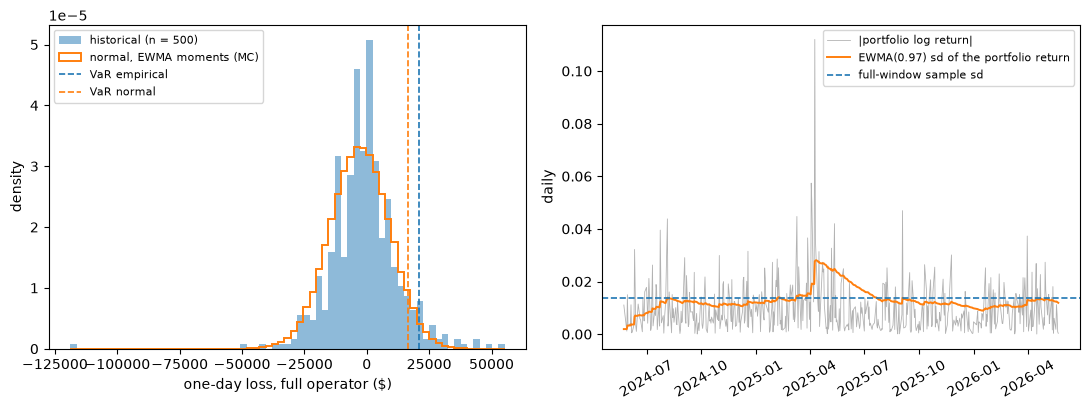

# Appendix: source code

The code below produces every figure and number above.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

ALPHA = 0.95
LAM = 0.97          # EWMA mean
THETA = 0.97        # EWMA covariance
DELTA = 1 / 252

plt.rcParams['figure.figsize'] = (11, 5)


def var_emp(losses, a):
    # VaR from a sample: the ceil(n*a)-th order statistic (Lemma 7 in the notes)
    ls = np.sort(np.asarray(losses))
    n = len(ls)
    return ls[int(np.ceil(n * a)) - 1]

In [2]:
# Daily closes, saved to csv so this runs offline. To pull fresh data instead:
#     import yfinance as yf
#     yf.download(['MSFT', 'AAPL', 'GOOGL'], start='2024-05-23', end='2026-05-23')['Close']
# (Yahoo's end date is exclusive, hence 05/23 to include 05/22.)
prices = pd.read_csv('stocks_daily.csv', parse_dates=['Date']).set_index('Date')
tickers = ['MSFT', 'AAPL', 'GOOGL']
prices = prices[tickers]

print('first five observations'); print(prices.head())
print('\nlast five observations'); print(prices.tail())
print('\nN =', len(prices), 'trading days,', prices.index[0].date(), '->', prices.index[-1].date())

first five observations
                  MSFT        AAPL       GOOGL
Date                                          
2024-05-23  427.000000  186.880005  173.550003
2024-05-24  430.160004  189.979996  174.990005
2024-05-28  430.320007  189.990005  176.399994
2024-05-29  429.170013  190.289993  175.899994
2024-05-30  414.670013  191.289993  172.110001

last five observations
                  MSFT        AAPL       GOOGL
Date                                          
2026-05-18  423.540009  297.839996  396.940002
2026-05-19  417.420013  298.970001  387.660004
2026-05-20  421.059998  302.250000  388.910004
2026-05-21  419.089996  304.989990  387.660004
2026-05-22  418.570007  308.820007  382.970001

N = 501 trading days, 2024-05-23 -> 2026-05-22


In [3]:
# log returns X_i = ln(S_i / S_{i-1}), one row per day, one column per stock
X = np.log(prices / prices.shift(1)).dropna()
x_hist = X.values
n_hist = len(x_hist)
print('log returns:', n_hist, 'rows')
print(X.describe().loc[['mean', 'std']].T)

log returns: 500 rows
           mean       std
MSFT  -0.000040  0.015632
AAPL   0.001005  0.017631
GOOGL  0.001583  0.019005


In [4]:
mcap = pd.Series({'MSFT': 3.109, 'AAPL': 4.536, 'GOOGL': 4.640})   # $ trillion, 05/22/2026
w = (mcap / mcap.sum())[tickers]
V0 = 1_000_000
S_t = prices.iloc[-1]
shares = V0 * w / S_t          # lambda_t^(i): shares held in each name

print('total market cap  $%.3f tn' % mcap.sum())
print('\nweights w_i'); print(w.round(6))
print('\nshares lambda_i at 05/22/2026 closes'); print(shares.round(2))
print('\ncheck: sum of weights =', round(w.sum(), 10), ' portfolio value =', round((shares * S_t).sum(), 2))

total market cap  $12.285 tn

weights w_i
MSFT     0.253073
AAPL     0.369231
GOOGL    0.377696
dtype: float64

shares lambda_i at 05/22/2026 closes
MSFT      604.61
AAPL     1195.62
GOOGL     986.23
dtype: float64

check: sum of weights = 1.0  portfolio value = 1000000.0


In [5]:
wv = w.values

def loss_full(x):
    # x: (n, 3) array of log returns
    return -V0 * ((np.exp(x) - 1) @ wv)

def loss_lin(x):
    return -V0 * (x @ wv)

def loss_quad(x):
    return -V0 * ((x + 0.5 * x**2) @ wv)

ops = [('full', loss_full), ('linear', loss_lin), ('quadratic', loss_quad)]

hist_var = {}
print('historical simulation, n = %d, alpha = %.2f, order statistic k = %d'
      % (n_hist, ALPHA, int(np.ceil(n_hist * ALPHA))))
for name, op in ops:
    L = op(x_hist)
    hist_var[name] = var_emp(L, ALPHA)
    print('%-10s  VaR = %9.2f   (mean %7.2f, sd %8.2f)' % (name, hist_var[name], L.mean(), L.std(ddof=1)))

historical simulation, n = 500, alpha = 0.95, order statistic k = 475
full        VaR =  21043.04   (mean -1116.04, sd 13918.52)
linear      VaR =  21415.73   (mean -958.72, sd 13831.42)
quadratic   VaR =  21038.61   (mean -1115.59, sd 13910.40)


In [6]:
mu = np.zeros(3)
Sig = np.zeros((3, 3))
for x in x_hist:
    d = x - mu                                    # uses mu_t, before it is updated
    Sig = THETA * Sig + (1 - THETA) * np.outer(d, d)
    mu = LAM * mu + (1 - LAM) * x

mu_s = pd.Series(mu, index=tickers)
Sig_df = pd.DataFrame(Sig, index=tickers, columns=tickers)
vol = np.sqrt(np.diag(Sig))
corr = Sig / np.outer(vol, vol)

print('EWMA mean (daily), as of 05/22/2026 for use on 05/25/2026')
print(mu_s.map('{:.6e}'.format))
print('\nEWMA covariance (daily)'); print(Sig_df.map('{:.4e}'.format))
print('\nannualized vol'); print(pd.Series(vol / np.sqrt(DELTA), index=tickers).round(4))
print('\ncorrelation'); print(pd.DataFrame(corr, index=tickers, columns=tickers).round(4))
print('\nweight on the initial (mu_0, Sigma_0) after %d steps: %.2e' % (n_hist, LAM**n_hist))

EWMA mean (daily), as of 05/22/2026 for use on 05/25/2026
MSFT     4.725682e-04
AAPL     3.636476e-03
GOOGL    3.305902e-03
dtype: str

EWMA covariance (daily)
             MSFT        AAPL       GOOGL
MSFT   3.1427e-04  3.4314e-05  3.4633e-06
AAPL   3.4314e-05  1.9268e-04  8.1376e-05
GOOGL  3.4633e-06  8.1376e-05  4.5938e-04

annualized vol
MSFT     0.2814
AAPL     0.2204
GOOGL    0.3402
dtype: float64

correlation
         MSFT    AAPL   GOOGL
MSFT   1.0000  0.1394  0.0091
AAPL   0.1394  1.0000  0.2735
GOOGL  0.0091  0.2735  1.0000

weight on the initial (mu_0, Sigma_0) after 500 steps: 2.43e-07


In [7]:
# linear operator: exact. L_lin ~ N(-V w'mu, V^2 w'Sigma w)
port_mu = wv @ mu
port_sd = np.sqrt(wv @ Sig @ wv)
var_lin_exact = -V0 * port_mu + V0 * port_sd * norm.ppf(ALPHA)
print('portfolio daily mean  %.6e   sd  %.6e' % (port_mu, port_sd))
print('linear VaR (analytic) = %.2f' % var_lin_exact)

portfolio daily mean  2.710920e-03   sd  1.190381e-02
linear VaR (analytic) = 16869.11


In [8]:
# full and quadratic operators: Monte Carlo from N(mu, Sigma)
N_MC = 100_000
rng = np.random.default_rng(731)
x_mc = rng.multivariate_normal(mu, Sig, size=N_MC)

norm_var = {}
print('Monte Carlo, N = %d, order statistic k = %d' % (N_MC, int(np.ceil(N_MC * ALPHA))))
for name, op in ops:
    L = op(x_mc)
    norm_var[name] = var_emp(L, ALPHA)
    print('%-10s  VaR = %9.2f   (mean %7.2f, sd %8.2f)' % (name, norm_var[name], L.mean(), L.std(ddof=1)))
print('\nMC linear vs analytic: %.2f vs %.2f  (diff %.2f)' % (norm_var['linear'], var_lin_exact,
                                                             norm_var['linear'] - var_lin_exact))
norm_var['linear'] = var_lin_exact      # report the exact number for the linear operator

Monte Carlo, N = 100000, order statistic k = 95000
full        VaR =  16609.78   (mean -2829.94, sd 11923.74)
linear      VaR =  16869.98   (mean -2663.14, sd 11886.33)
quadratic   VaR =  16605.55   (mean -2829.50, sd 11921.52)

MC linear vs analytic: 16869.98 vs 16869.11  (diff 0.87)


In [9]:
comp = pd.DataFrame({'empirical': hist_var, 'normal (EWMA)': norm_var}).loc[['full', 'linear', 'quadratic']]
print(comp.round(2))
print('\nrelative to full, empirical:   lin %+.2f%%  quad %+.2f%%'
      % (100 * (hist_var['linear'] / hist_var['full'] - 1), 100 * (hist_var['quadratic'] / hist_var['full'] - 1)))
print('relative to full, normal:      lin %+.2f%%  quad %+.2f%%'
      % (100 * (norm_var['linear'] / norm_var['full'] - 1), 100 * (norm_var['quadratic'] / norm_var['full'] - 1)))
print('normal / empirical, full operator: %.3f' % (norm_var['full'] / hist_var['full']))

# where the historical window's volatility sits relative to the EWMA estimate
port_ret = x_hist @ wv
print('\nportfolio log-return sd:   whole window %.4e   EWMA(0.97) at 05/22 %.4e'
      % (port_ret.std(ddof=1), port_sd))
print('full-window sample VaR under normal with sample moments: %.2f'
      % (-V0 * port_ret.mean() + V0 * port_ret.std(ddof=1) * norm.ppf(ALPHA)))

           empirical  normal (EWMA)
full        21043.04       16609.78
linear      21415.73       16869.11
quadratic   21038.61       16605.55

relative to full, empirical:   lin +1.77%  quad -0.02%
relative to full, normal:      lin +1.56%  quad -0.03%
normal / empirical, full operator: 0.789

portfolio log-return sd:   whole window 1.3831e-02   EWMA(0.97) at 05/22 1.1904e-02
full-window sample VaR under normal with sample moments: 21791.95


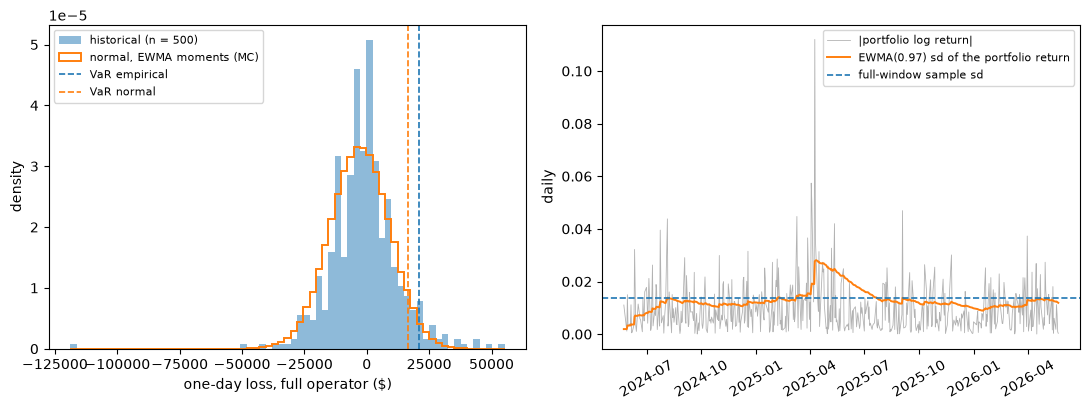

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

L_h = loss_full(x_hist)
L_n = loss_full(x_mc)
bins = np.linspace(min(L_h.min(), np.quantile(L_n, 0.001)), max(L_h.max(), np.quantile(L_n, 0.999)), 70)
ax[0].hist(L_h, bins=bins, density=True, alpha=0.5, label='historical (n = %d)' % n_hist)
ax[0].hist(L_n, bins=bins, density=True, histtype='step', lw=1.4, label='normal, EWMA moments (MC)')
ax[0].axvline(hist_var['full'], color='C0', ls='--', lw=1.2, label='VaR empirical')
ax[0].axvline(norm_var['full'], color='C1', ls='--', lw=1.2, label='VaR normal')
ax[0].set_xlabel('one-day loss, full operator ($)')
ax[0].set_ylabel('density')
ax[0].legend(fontsize=8)

# EWMA portfolio vol through the sample, to see where 05/22/2026 sits
mu_p, s2_p, ewma_sd = 0.0, 0.0, np.empty(n_hist)
for i, xp in enumerate(port_ret):
    s2_p = THETA * s2_p + (1 - THETA) * (xp - mu_p)**2
    mu_p = LAM * mu_p + (1 - LAM) * xp
    ewma_sd[i] = np.sqrt(s2_p)
ax[1].plot(X.index, np.abs(port_ret), color='grey', lw=0.6, alpha=0.6, label='|portfolio log return|')
ax[1].plot(X.index, ewma_sd, color='C1', lw=1.4, label='EWMA(0.97) sd of the portfolio return')
ax[1].axhline(port_ret.std(ddof=1), color='C0', ls='--', lw=1.2, label='full-window sample sd')
ax[1].set_ylabel('daily')
ax[1].legend(fontsize=8)
ax[1].tick_params(axis='x', labelrotation=30)

fig.tight_layout()
plt.show()